In [1]:
!pip install -q datasets

In [2]:
from datasets import load_dataset
import pandas as pd
import numpy as np

civil = load_dataset(
    "google/civil_comments",
    split="train"
)

civil_df = civil.to_pandas()

print("Civil Comments Shape:", civil_df.shape)
print(civil_df.columns.tolist())

README.md:   0%|          | 0.00/7.73k [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  194MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  187MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

...

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1804874 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/97320 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/97320 [00:00<?, ? examples/s]

Civil Comments Shape: (1804874, 8)
['text', 'toxicity', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit']


In [3]:
label_mapping = {
    "toxicity": "toxic",
    "severe_toxicity": "severe_toxic",
    "obscene": "obscene",
    "threat": "threat",
    "insult": "insult",
    "identity_attack": "identity_hate"
}

civil_df = civil_df[
    ["text"] + list(label_mapping.keys())
].copy()

civil_df.rename(
    columns=label_mapping,
    inplace=True
)

civil_df.head()

,text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,"This is so cool. It's like, 'would you want yo...",0.000000,0.000000,0.0,0.0,0.00000,0.000000
1,Thank you!! This would make my life a lot less...,0.000000,0.000000,0.0,0.0,0.00000,0.000000
2,This is such an urgent design problem; kudos t...,0.000000,0.000000,0.0,0.0,0.00000,0.000000
3,Is this something I'll be able to install on m...,0.000000,0.000000,0.0,0.0,0.00000,0.000000
4,haha you guys are a bunch of losers.,0.893617,0.021277,0.0,0.0,0.87234,0.021277


In [4]:
labels = [
    "toxic",
    "severe_toxic",
    "obscene",
    "threat",
    "insult",
    "identity_hate"
]

THRESHOLD = 0.5

for col in labels:
    civil_df[col] = (
        civil_df[col] >= THRESHOLD
    ).astype("int8")

In [5]:
for col in labels:
    positive = civil_df[col].sum()
    negative = len(civil_df) - positive

    print(
        f"{col}: Positive={positive}, "
        f"Negative={negative}, "
        f"Positive %={positive/len(civil_df)*100:.3f}"
    )

toxic: Positive=144334, Negative=1660540, Positive %=7.997
severe_toxic: Positive=13, Negative=1804861, Positive %=0.001
obscene: Positive=9603, Negative=1795271, Positive %=0.532
threat: Positive=4280, Negative=1800594, Positive %=0.237
insult: Positive=106534, Negative=1698340, Positive %=5.903
identity_hate: Positive=13410, Negative=1791464, Positive %=0.743


In [6]:
jigsaw_df = pd.read_csv(
    "/kaggle/input/datasets/julian3833/jigsaw-toxic-comment-classification-challenge/train.csv"
)

print(jigsaw_df.shape)

(159571, 8)


In [7]:
required_columns = [
    "comment_text",
    "toxic",
    "severe_toxic",
    "obscene",
    "threat",
    "insult",
    "identity_hate"
]

jigsaw_df = jigsaw_df[required_columns].copy()

jigsaw_df.rename(
    columns={"comment_text": "text"},
    inplace=True
)

In [8]:
def normalize_text(text):
    return (
        str(text)
        .lower()
        .strip()
    )

jigsaw_df["text_clean"] = jigsaw_df["text"].apply(
    normalize_text
)

civil_df["text_clean"] = civil_df["text"].apply(
    normalize_text
)

existing_texts = set(jigsaw_df["text_clean"])

civil_df = civil_df[
    ~civil_df["text_clean"].isin(existing_texts)
].copy()

print("Civil Comments after duplicate removal:",
      civil_df.shape)

Civil Comments after duplicate removal: (1804711, 8)


In [9]:
targets = {
    "toxic": 30000,
    "severe_toxic": 5000,
    "obscene": 20000,
    "threat": 8000,
    "insult": 25000,
    "identity_hate": 8000
}

current_counts = jigsaw_df[labels].sum()

remaining = {
    col: max(0, targets[col] - current_counts[col])
    for col in labels
}

selected = set()

priority = [
    "threat",
    "identity_hate",
    "insult",
    "obscene",
    "toxic",
    "severe_toxic"
]

civil_df = civil_df.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

for label in priority:

    needed = remaining[label]

    candidates = civil_df[
        (civil_df[label] == 1) &
        (~civil_df.index.isin(selected))
    ]

    take = min(needed, len(candidates))

    if take > 0:
        chosen = candidates.sample(
            n=take,
            random_state=42
        )

        selected.update(chosen.index)

civil_selected = civil_df.loc[list(selected)]

print("Selected samples:", len(civil_selected))

Selected samples: 51213


In [10]:
for col in labels:
    positive = civil_selected[col].sum()
    negative = len(civil_selected) - positive

    print(
        f"{col}: Positive={positive}, "
        f"Negative={negative}, "
        f"Positive %={positive/len(civil_selected)*100:.3f}%"
    )

toxic: Positive=50058, Negative=1155, Positive %=97.745%
severe_toxic: Positive=13, Negative=51200, Positive %=0.025%
obscene: Positive=9601, Negative=41612, Positive %=18.747%
threat: Positive=4280, Negative=46933, Positive %=8.357%
insult: Positive=34794, Negative=16419, Positive %=67.940%
identity_hate: Positive=8068, Negative=43145, Positive %=15.754%


In [11]:
# Select additional negative samples

negative_candidates = civil_df[
    (civil_df["toxic"] == 0) &
    (~civil_df.index.isin(selected))
].copy()

additional_negative = negative_candidates.sample(
    n=min(20000, len(negative_candidates)),
    random_state=42
)

print("Additional negative samples:", len(additional_negative))

Additional negative samples: 20000


In [12]:
civil_final = pd.concat(
    [civil_selected, additional_negative],
    ignore_index=True
)

civil_final = civil_final.drop_duplicates(
    subset=["text"],
    keep="first"
)

print("Civil Final Shape:", civil_final.shape)

Civil Final Shape: (70875, 8)


In [13]:
for col in labels:

    positive = civil_final[col].sum()
    negative = len(civil_final) - positive

    print(
        f"{col}: Positive={positive}, "
        f"Negative={negative}, "
        f"Positive %={positive/len(civil_final)*100:.3f}%"
    )

toxic: Positive=49754, Negative=21121, Positive %=70.200%
severe_toxic: Positive=13, Negative=70862, Positive %=0.018%
obscene: Positive=9515, Negative=61360, Positive %=13.425%
threat: Positive=4244, Negative=66631, Positive %=5.988%
insult: Positive=34603, Negative=36272, Positive %=48.823%
identity_hate: Positive=8038, Negative=62837, Positive %=11.341%


In [14]:
# Keep only required columns

jigsaw_final = jigsaw_df[["text"] + labels].copy()

civil_final = civil_final[["text"] + labels].copy()

# Merge datasets

merged_df = pd.concat(
    [jigsaw_final, civil_final],
    ignore_index=True
)

# Remove duplicate comments

merged_df["text_clean"] = (
    merged_df["text"].astype(str).str.lower().str.strip()
)

merged_df = merged_df.drop_duplicates(
    subset=["text_clean"],
    keep="first"
)

merged_df = merged_df.drop(
    columns=["text_clean"]
)

merged_df = merged_df.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print("Final Dataset Shape:", merged_df.shape)

Final Dataset Shape: (230364, 7)


In [15]:
distribution = []

for col in labels:

    positive = int(merged_df[col].sum())
    negative = len(merged_df) - positive

    distribution.append({
        "Label": col,
        "Positive": positive,
        "Negative": negative,
        "Positive %": round(
            positive / len(merged_df) * 100, 3
        )
    })

distribution_df = pd.DataFrame(distribution)

display(distribution_df)

,Label,Positive,Negative,Positive %
0,toxic,65004,165360,28.218
1,severe_toxic,1606,228758,0.697
2,obscene,17947,212417,7.791
3,threat,4718,225646,2.048
4,insult,42453,187911,18.429
5,identity_hate,9438,220926,4.097


In [21]:
import tensorflow as tf
import keras
import keras_hub
import numpy as np

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.20.0
Keras: 3.13.2
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [22]:
labels = [
    "toxic",
    "severe_toxic",
    "obscene",
    "threat",
    "insult",
    "identity_hate"
]

pos_weights = tf.constant(
    [1.772, 71.720, 6.418, 24.413, 2.713, 12.204],
    dtype=tf.float32
)

neg_weights = tf.constant(
    [0.697, 0.504, 0.542, 0.510, 0.613, 0.521],
    dtype=tf.float32
)

In [23]:
!pip install -q iterative-stratification

In [26]:
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

X = merged_df["text"].values
y = merged_df[labels].values.astype("int32")

msss = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, val_idx = next(
    msss.split(X, y)
)

train_df = merged_df.iloc[train_idx].reset_index(drop=True)
val_df = merged_df.iloc[val_idx].reset_index(drop=True)

print("Training Shape:", train_df.shape)
print("Validation Shape:", val_df.shape)

Training Shape: (184291, 7)
Validation Shape: (46073, 7)


In [27]:
for label in labels:

    train_pos = train_df[label].sum()
    val_pos = val_df[label].sum()

    print(f"\n{label}")
    print("Train Positive:", train_pos)
    print("Validation Positive:", val_pos)
    print("Train Positive %:", round(train_pos / len(train_df) * 100, 3))
    print("Validation Positive %:", round(val_pos / len(val_df) * 100, 3))


toxic
Train Positive: 52003
Validation Positive: 13001
Train Positive %: 28.218
Validation Positive %: 28.218

severe_toxic
Train Positive: 1285
Validation Positive: 321
Train Positive %: 0.697
Validation Positive %: 0.697

obscene
Train Positive: 14358
Validation Positive: 3589
Train Positive %: 7.791
Validation Positive %: 7.79

threat
Train Positive: 3774
Validation Positive: 944
Train Positive %: 2.048
Validation Positive %: 2.049

insult
Train Positive: 33962
Validation Positive: 8491
Train Positive %: 18.428
Validation Positive %: 18.429

identity_hate
Train Positive: 7550
Validation Positive: 1888
Train Positive %: 4.097
Validation Positive %: 4.098


In [28]:
N = len(train_df)

pos_weights = []
neg_weights = []

for label in labels:

    pos = train_df[label].sum()
    neg = N - pos

    pos_weight = N / (2 * pos)
    neg_weight = N / (2 * neg)

    pos_weights.append(pos_weight)
    neg_weights.append(neg_weight)

    print(
        f"{label}: Positive Weight={pos_weight:.3f}, "
        f"Negative Weight={neg_weight:.3f}"
    )

pos_weights = tf.constant(pos_weights, dtype=tf.float32)
neg_weights = tf.constant(neg_weights, dtype=tf.float32)

toxic: Positive Weight=1.772, Negative Weight=0.697
severe_toxic: Positive Weight=71.709, Negative Weight=0.504
obscene: Positive Weight=6.418, Negative Weight=0.542
threat: Positive Weight=24.416, Negative Weight=0.510
insult: Positive Weight=2.713, Negative Weight=0.613
identity_hate: Positive Weight=12.205, Negative Weight=0.521


In [29]:
import tensorflow as tf

pos_weights = tf.constant(
    [1.772, 71.709, 6.418, 24.416, 2.713, 12.205],
    dtype=tf.float32
)

neg_weights = tf.constant(
    [0.697, 0.504, 0.542, 0.510, 0.613, 0.521],
    dtype=tf.float32
)

def weighted_bce(y_true, y_pred):

    y_true = tf.cast(y_true, tf.float32)

    y_pred = tf.clip_by_value(
        y_pred,
        1e-7,
        1.0 - 1e-7
    )

    loss = -(
        y_true * tf.math.log(y_pred) * pos_weights
        +
        (1.0 - y_true) * tf.math.log(1.0 - y_pred) * neg_weights
    )

    return tf.reduce_mean(loss, axis=-1)

In [30]:
print(train_df.columns.tolist())
print(train_df.shape)
print(val_df.shape)

['text', 'toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']
(184291, 7)
(46073, 7)


In [31]:
print(train_df.columns.tolist())
print(train_df.shape)
print(val_df.shape)

['text', 'toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']
(184291, 7)
(46073, 7)


In [32]:
X_train = train_df["text"].astype(str).values
y_train = train_df[labels].values.astype("float32")

X_val = val_df["text"].astype(str).values
y_val = val_df[labels].values.astype("float32")

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

X_train: (184291,)
y_train: (184291, 6)
X_val: (46073,)
y_val: (46073, 6)


In [33]:
BATCH_SIZE = 32

train_dataset = tf.data.Dataset.from_tensor_slices(
    (X_train, y_train)
)

train_dataset = (
    train_dataset
    .shuffle(10000)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

val_dataset = tf.data.Dataset.from_tensor_slices(
    (X_val, y_val)
)

val_dataset = (
    val_dataset
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

In [34]:
for x, y in train_dataset.take(1):
    print("Input batch shape:", x.shape)
    print("Output batch shape:", y.shape)

Input batch shape: (32,)
Output batch shape: (32, 6)


In [35]:
import keras_hub

backbone = keras_hub.models.DistilBertBackbone.from_preset(
    "distil_bert_base_en_uncased"
)

In [36]:
preprocessor = keras_hub.models.DistilBertPreprocessor.from_preset(
    "distil_bert_base_en_uncased",
    sequence_length=128
)

In [37]:
import keras
import tensorflow as tf

text_input = keras.Input(
    shape=(),
    dtype="string",
    name="text"
)

# Text preprocessing
x = preprocessor(text_input)

# DistilBERT feature extraction
x = backbone(x)

# CLS token representation
x = x[:, 0, :]

# Dropout
x = keras.layers.Dropout(0.3)(x)

# Classification layer
output = keras.layers.Dense(
    6,
    activation="sigmoid",
    name="predictions"
)(x)

# Final model
model = keras.Model(
    inputs=text_input,
    outputs=output
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ text (InputLayer)   │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ distil_bert_text_c… │ [(None, 128),     │          0 │ text[0][0]        │
│ (DistilBertTextCla… │ (None, 128)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ distil_bert_backbo… │ (None, 128, 768)  │ 66,362,880 │ distil_bert_text… │
│ (DistilBertBackbon… │                   │            │ distil_bert_text… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 768)       │          0 │ distil_bert_back… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, 768)       │          0 │ get_item[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ predictions (Dense) │ (None, 6)         │      4,614 │ dropout_6[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 66,367,494 (253.17 MB)

 Trainable params: 66,367,494 (253.17 MB)

 Non-trainable params: 0 (0.00 B)

In [40]:
model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=2e-5
    ),
    loss=weighted_bce,
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy")
    ],
    jit_compile=False
)

In [41]:
sample_predictions = model.predict(
    X_train[:2],
    verbose=1
)

print("Output shape:", sample_predictions.shape)
print("Predictions:\n", sample_predictions)

1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
Output shape: (2, 6)
Predictions:
 [[0.7381184  0.41428465 0.76877385 0.5468537  0.43398616 0.51994824]
 [0.706381   0.49677733 0.69566715 0.5686459  0.4615579  0.468329  ]]


In [42]:
callbacks = [
    keras.callbacks.ModelCheckpoint(
        "best_weighted_distilbert.keras",
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),

    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True,
        verbose=1
    )
]

history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=3,
    callbacks=callbacks
)

Epoch 1/3
5760/5760 ━━━━━━━━━━━━━━━━━━━━ 0s 480ms/step - accuracy: 0.8951 - loss: 0.2355
Epoch 1: val_loss improved from None to 0.15115, saving model to best_weighted_distilbert.keras

Epoch 1: finished saving model to best_weighted_distilbert.keras
5760/5760 ━━━━━━━━━━━━━━━━━━━━ 2997s 517ms/step - accuracy: 0.9225 - loss: 0.1855 - val_accuracy: 0.9372 - val_loss: 0.1511
Epoch 2/3
5760/5760 ━━━━━━━━━━━━━━━━━━━━ 0s 479ms/step - accuracy: 0.9443 - loss: 0.1355
Epoch 2: val_loss did not improve from 0.15115
5760/5760 ━━━━━━━━━━━━━━━━━━━━ 2971s 516ms/step - accuracy: 0.9464 - loss: 0.1285 - val_accuracy: 0.9471 - val_loss: 0.1593
Epoch 3/3
5760/5760 ━━━━━━━━━━━━━━━━━━━━ 0s 479ms/step - accuracy: 0.9524 - loss: 0.1123
Epoch 3: val_loss did not improve from 0.15115
5760/5760 ━━━━━━━━━━━━━━━━━━━━ 2970s 516ms/step - accuracy: 0.9543 - loss: 0.1063 - val_accuracy: 0.9513 - val_loss: 0.1612
Epoch 3: early stopping
Restoring model weights from the end of the best epoch: 1.


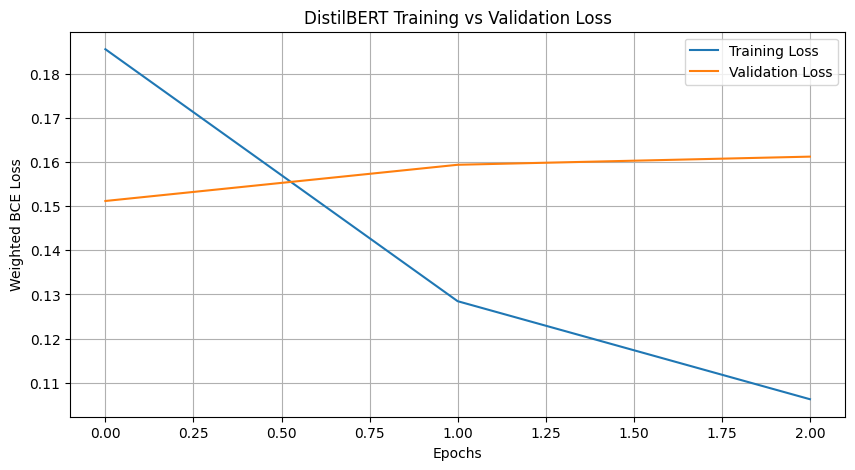

In [43]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Weighted BCE Loss")
plt.title("DistilBERT Training vs Validation Loss")

plt.legend()
plt.grid(True)
plt.show()

In [44]:
y_pred = model.predict(val_dataset)

print("Prediction Shape:", y_pred.shape)
print("Actual Shape:", y_val.shape)

1440/1440 ━━━━━━━━━━━━━━━━━━━━ 213s 147ms/step
Prediction Shape: (46073, 6)
Actual Shape: (46073, 6)


In [45]:
from sklearn.metrics import classification_report

y_pred_binary = (y_pred >= 0.5).astype(int)

print(classification_report(
    y_val,
    y_pred_binary,
    target_names=labels,
    zero_division=0
))

               precision    recall  f1-score   support

        toxic       0.80      0.96      0.87     13001
 severe_toxic       0.15      0.97      0.27       321
      obscene       0.62      0.94      0.75      3589
       threat       0.36      0.93      0.52       944
       insult       0.61      0.97      0.75      8491
identity_hate       0.41      0.95      0.57      1888

    micro avg       0.63      0.96      0.76     28234
    macro avg       0.49      0.95      0.62     28234
 weighted avg       0.67      0.96      0.78     28234
  samples avg       0.22      0.28      0.24     28234



In [46]:
from sklearn.metrics import average_precision_score

for i, label in enumerate(labels):
    score = average_precision_score(y_val[:, i], y_pred[:, i])
    print(f"{label}: {score:.4f}")

toxic: 0.9528
severe_toxic: 0.4571
obscene: 0.8642
threat: 0.7938
insult: 0.8933
identity_hate: 0.7961


In [47]:
import numpy as np
import pandas as pd
from sklearn.metrics import precision_recall_curve

threshold_results = []

optimal_thresholds = []

for i, label in enumerate(labels):

    precision, recall, thresholds = precision_recall_curve(
        y_val[:, i],
        y_pred[:, i]
    )

    # Calculate F1 score
    f1_scores = (
        2 * precision[:-1] * recall[:-1]
        / (precision[:-1] + recall[:-1] + 1e-8)
    )

    best_idx = np.argmax(f1_scores)

    best_threshold = thresholds[best_idx]
    best_f1 = f1_scores[best_idx]

    optimal_thresholds.append(best_threshold)

    threshold_results.append({
        "Label": label,
        "Optimal Threshold": round(best_threshold, 4),
        "Precision": round(precision[best_idx], 4),
        "Recall": round(recall[best_idx], 4),
        "F1 Score": round(best_f1, 4)
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df)

,Label,Optimal Threshold,Precision,Recall,F1 Score
0,toxic,0.7576,0.8702,0.9132,0.8912
1,severe_toxic,0.9826,0.4455,0.5857,0.5061
2,obscene,0.9038,0.7742,0.8629,0.8162
3,threat,0.9778,0.7623,0.7203,0.7407
4,insult,0.8486,0.7822,0.8584,0.8185
5,identity_hate,0.9522,0.7211,0.7558,0.7380


In [48]:
from sklearn.metrics import classification_report

optimal_thresholds = np.array(optimal_thresholds)

y_pred_tuned = (
    y_pred >= optimal_thresholds.reshape(1, -1)
).astype(int)

print(classification_report(
    y_val,
    y_pred_tuned,
    target_names=labels,
    zero_division=0
))

               precision    recall  f1-score   support

        toxic       0.87      0.91      0.89     13001
 severe_toxic       0.45      0.59      0.51       321
      obscene       0.77      0.86      0.82      3589
       threat       0.76      0.72      0.74       944
       insult       0.78      0.86      0.82      8491
identity_hate       0.72      0.76      0.74      1888

    micro avg       0.81      0.87      0.84     28234
    macro avg       0.73      0.78      0.75     28234
 weighted avg       0.81      0.87      0.84     28234
  samples avg       0.24      0.25      0.24     28234



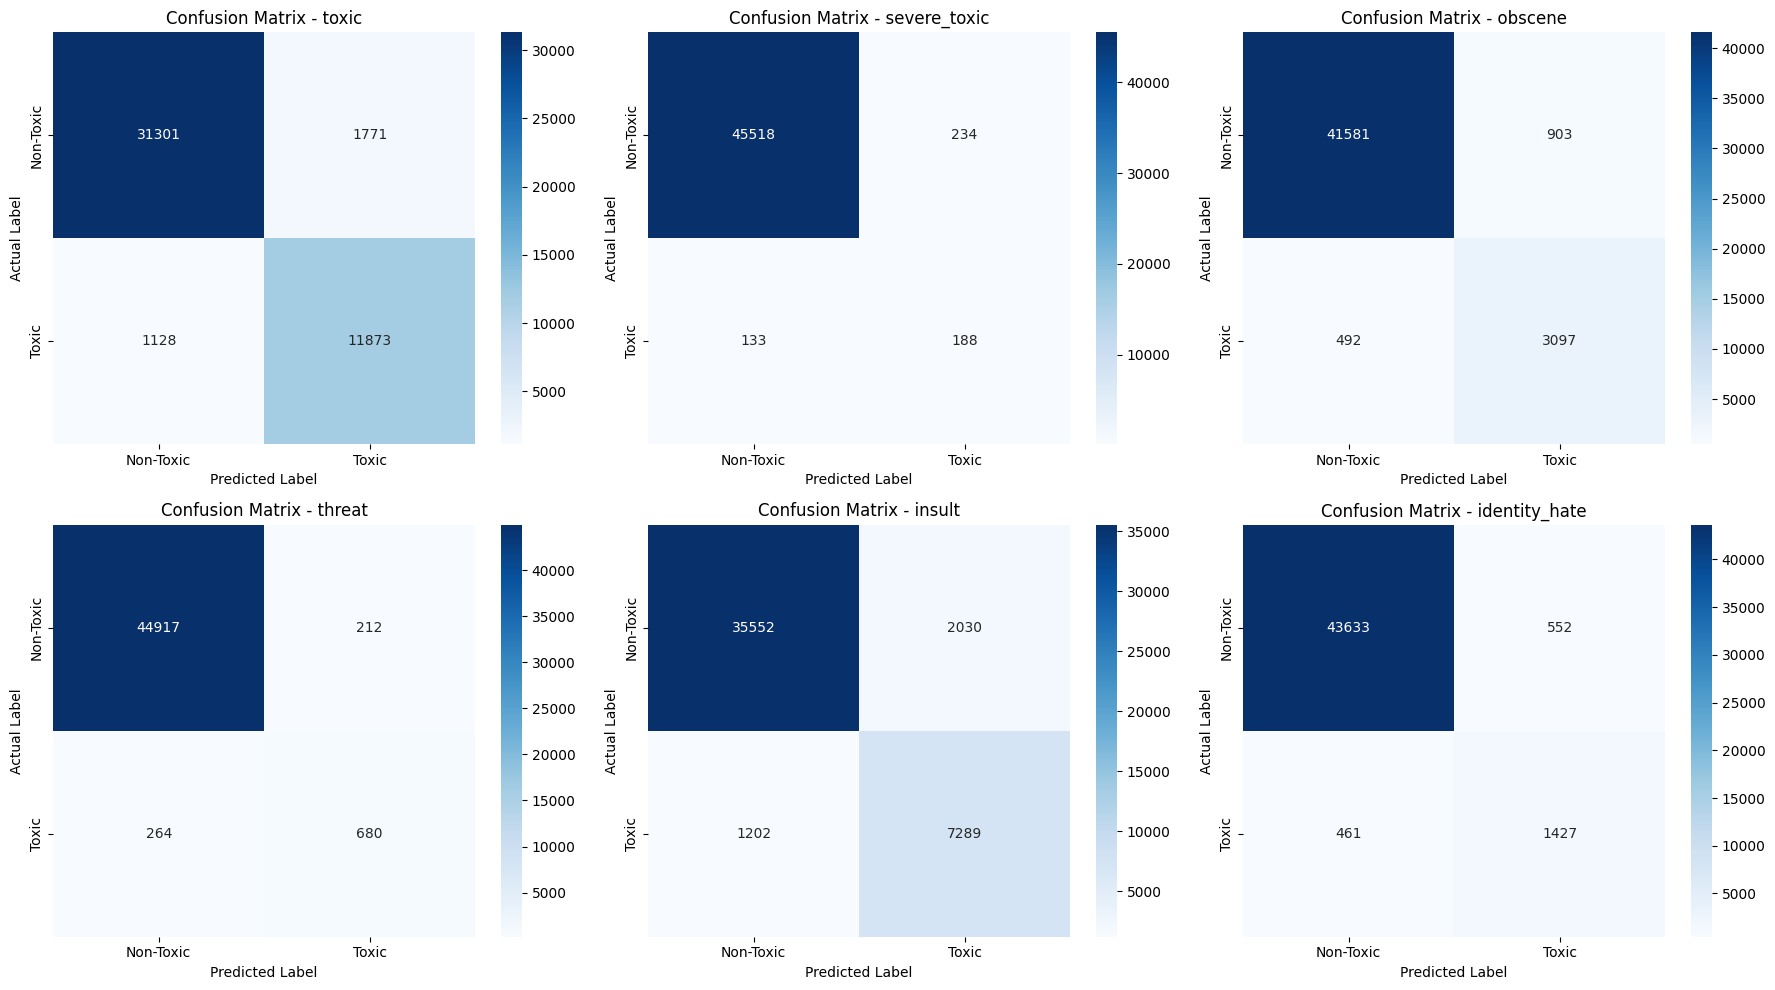

In [49]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for i, label in enumerate(labels):

    cm = confusion_matrix(
        y_val[:, i],
        y_pred_tuned[:, i]
    )

    ax = axes[i // 3, i % 3]

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Non-Toxic", "Toxic"],
        yticklabels=["Non-Toxic", "Toxic"],
        ax=ax
    )

    ax.set_title(f"Confusion Matrix - {label}")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.show()

In [50]:
model.save("best_weighted_distilbert.keras")

print("Model saved successfully!")

Model saved successfully!


In [51]:
import json

threshold_dict = {
    label: float(threshold)
    for label, threshold in zip(labels, optimal_thresholds)
}

with open("optimal_thresholds.json", "w") as f:
    json.dump(threshold_dict, f, indent=4)

print("Thresholds saved successfully!")

Thresholds saved successfully!


In [52]:
from IPython.display import FileLink, display

# Model download
display(FileLink("best_weighted_distilbert.keras"))

# Thresholds download
display(FileLink("optimal_thresholds.json"))

/kaggle/working/best_weighted_distilbert.keras

/kaggle/working/optimal_thresholds.json

In [1]:
import pandas as pd

test_df = pd.read_csv(
    "/kaggle/input/datasets/julian3833/jigsaw-toxic-comment-classification-challenge/test.csv"
)

test_labels_df = pd.read_csv(
    "/kaggle/input/datasets/julian3833/jigsaw-toxic-comment-classification-challenge/test_labels.csv"
)

print("Test Shape:", test_df.shape)
print("Test Labels Shape:", test_labels_df.shape)

display(test_df.head())
display(test_labels_df.head())

Test Shape: (153164, 2)
Test Labels Shape: (153164, 7)


,id,comment_text
0,00001cee341fdb12,Yo bitch Ja Rule is more succesful then you'll...
1,0000247867823ef7,== From RfC == \n\n The title is fine as it is...
2,00013b17ad220c46,""" \n\n == Sources == \n\n * Zawe Ashton on Lap..."
3,00017563c3f7919a,":If you have a look back at the source, the in..."
4,00017695ad8997eb,I don't anonymously edit articles at all.


,id,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,00001cee341fdb12,-1,-1,-1,-1,-1,-1
1,0000247867823ef7,-1,-1,-1,-1,-1,-1
2,00013b17ad220c46,-1,-1,-1,-1,-1,-1
3,00017563c3f7919a,-1,-1,-1,-1,-1,-1
4,00017695ad8997eb,-1,-1,-1,-1,-1,-1


In [2]:
test_merged = test_df.merge(
    test_labels_df,
    on="id",
    how="inner"
)

print("Merged Test Shape:", test_merged.shape)

Merged Test Shape: (153164, 8)


In [4]:
labels = [
    "toxic",
    "severe_toxic",
    "obscene",
    "threat",
    "insult",
    "identity_hate"
]

In [5]:
print(test_merged[labels].apply(pd.Series.value_counts))

    toxic  severe_toxic  obscene  threat  insult  identity_hate
-1  89186         89186    89186   89186   89186          89186
 0  57888         63611    60287   63767   60551          63266
 1   6090           367     3691     211    3427            712


In [6]:
test_merged = test_merged[
    (test_merged[labels] != -1).all(axis=1)
].copy()

print("Valid Test Shape:", test_merged.shape)

Valid Test Shape: (63978, 8)


In [7]:
X_test = test_merged["comment_text"].fillna("").astype(str).values

y_test = test_merged[labels].values.astype("float32")

print("X_test Shape:", X_test.shape)
print("y_test Shape:", y_test.shape)

X_test Shape: (63978,)
y_test Shape: (63978, 6)


In [15]:
import keras
import keras_hub
import tensorflow as tf
import zipfile
import os

PRESET = "distil_bert_base_en_uncased"

preprocessor = keras_hub.models.DistilBertPreprocessor.from_preset(
    PRESET,
    sequence_length=128
)

backbone = keras_hub.models.DistilBertBackbone.from_preset(PRESET)

print("Vocabulary Size:", preprocessor.tokenizer.vocabulary_size())

Vocabulary Size: 30522


In [19]:
text_input = keras.Input(
    shape=(),
    dtype="string",
    name="text"
)

x = preprocessor(text_input)
x = backbone(x)
x = x[:, 0, :]

x = keras.layers.Dropout(0.3)(x)

output = keras.layers.Dense(
    6,
    activation="sigmoid",
    name="predictions"
)(x)

model = keras.Model(
    inputs=text_input,
    outputs=output
)

print("Architecture reconstructed!")

Architecture reconstructed!


In [20]:
model_path = "/kaggle/input/models/deepakvarshney1245/content-moderation/keras/1/1/best_weighted_distilbert.keras"

In [21]:
with zipfile.ZipFile(model_path, "r") as zip_ref:
    for name in zip_ref.namelist():
        print(name)

metadata.json
config.json
model.weights.h5
assets/layers/distil_bert_text_classifier_preprocessor/tokenizer/vocabulary.txt


In [22]:
with zipfile.ZipFile(model_path, "r") as zip_ref:

    weights_file = [
        name for name in zip_ref.namelist()
        if name.endswith("model.weights.h5")
    ]

    print("Found:", weights_file)

    if not weights_file:
        raise FileNotFoundError("Model weights file not found!")

    zip_ref.extract(
        weights_file[0],
        "/kaggle/working/"
    )

extracted_weights = os.path.join(
    "/kaggle/working/",
    weights_file[0]
)

print("Weights extracted:", extracted_weights)

Found: ['model.weights.h5']
Weights extracted: /kaggle/working/model.weights.h5


In [23]:
model.load_weights(extracted_weights)

print("Trained weights loaded successfully!")

Trained weights loaded successfully!


In [24]:
sample_text = tf.constant([
    "You are a wonderful person.",
    "I hate you."
])

predictions = model.predict(sample_text)

print("Prediction Shape:", predictions.shape)
print(predictions)

InvalidArgumentError: Graph execution error:

Detected at node data defined at (most recent call last):
  File "<frozen runpy>", line 203, in _run_module_as_main

  File "<frozen runpy>", line 88, in _run_code

  File "/usr/local/lib/python3.13/dist-packages/colab_kernel_launcher.py", line 37, in <module>

  File "/usr/local/lib/python3.13/dist-packages/traitlets/config/application.py", line 1080, in launch_instance

  File "/usr/local/lib/python3.13/dist-packages/ipykernel/kernelapp.py", line 712, in start

  File "/usr/local/lib/python3.13/dist-packages/tornado/platform/asyncio.py", line 211, in start

  File "/usr/lib/python3.13/asyncio/base_events.py", line 684, in run_forever

  File "/usr/lib/python3.13/asyncio/base_events.py", line 2061, in _run_once

  File "/usr/lib/python3.13/asyncio/events.py", line 89, in _run

  File "/usr/local/lib/python3.13/dist-packages/ipykernel/kernelbase.py", line 510, in dispatch_queue

  File "/usr/local/lib/python3.13/dist-packages/ipykernel/kern